In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Nosso projeto de análise de vendas começou!")
print("Pandas, NumPy e Matplotlib carregados com sucesso!")

Nosso projeto de análise de vendas começou!
Pandas, NumPy e Matplotlib carregados com sucesso!


In [2]:
Import pandas as pd

SyntaxError: invalid syntax (1084947998.py, line 1)

In [3]:
import pandas as pd

In [4]:
import pandas as pd

df = pd.read_excel("data/Online Retail.xlsx")

df.head()

FileNotFoundError: [Errno 2] No such file or directory: 'data/Online Retail.xlsx'

In [5]:
import os

print("Pasta atual:", os.getcwd())
print("Arquivos na pasta:", os.listdir())

Pasta atual: f:\Faculdade\Projeto analise venda
Arquivos na pasta: ['analise_vendas.ipynb', 'data']


In [6]:
import os

print(os.listdir("data"))

['raw']


In [7]:
import os

print(os.listdir("data/raw"))

['Online Retail.xlsx']


In [8]:
import pandas as pd

df = pd.read_excel("data/raw/Online Retail.xlsx")

df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [9]:
print("Quantidade de linhas e colunas:", df.shape)

Quantidade de linhas e colunas: (541909, 8)


In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


In [11]:

ausentes = df.isnull().sum()

diagnostico = pd.DataFrame({
    "Valores ausentes": ausentes,
    "Percentual (%)": (ausentes / len(df) * 100).round(2)
})

diagnostico


,Valores ausentes,Percentual (%)
InvoiceNo,0,0.00
StockCode,0,0.00
Description,1454,0.27
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
CustomerID,135080,24.93
Country,0,0.00


In [12]:

print("Quantidades negativas:", (df["Quantity"] < 0).sum())
print("Preços zerados:", (df["UnitPrice"] == 0).sum())
print("Preços negativos:", (df["UnitPrice"] < 0).sum())
print("Faturas com prefixo C:", df["InvoiceNo"].astype(str).str.startswith("C").sum())


Quantidades negativas: 10624
Preços zerados: 2515
Preços negativos: 2
Faturas com prefixo C: 9288


In [13]:

# Separar as faturas que começam com C
cancelamentos = df[
    df["InvoiceNo"].astype(str).str.startswith("C")
]

# Mostrar 10 exemplos para investigação
cancelamentos[
    ["InvoiceNo", "StockCode", "Description",
     "Quantity", "UnitPrice", "InvoiceDate"]
].head(10)


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,InvoiceDate
141,C536379,D,Discount,-1,27.50,2010-12-01 09:41:00
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,4.65,2010-12-01 09:49:00
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,1.65,2010-12-01 10:24:00
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,0.29,2010-12-01 10:24:00
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,0.29,2010-12-01 10:24:00
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,0.29,2010-12-01 10:24:00
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,3.45,2010-12-01 10:24:00
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,1.65,2010-12-01 10:24:00
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,1.65,2010-12-01 10:24:00
939,C536506,22960,JAM MAKING SET WITH JARS,-6,4.25,2010-12-01 12:38:00


In [14]:

df["TotalVenda"] = df["Quantity"] * df["UnitPrice"]

print("Faturamento líquido registrado: £", round(df["TotalVenda"].sum(), 2))

print("Total de linhas com valor negativo:",
      (df["TotalVenda"] < 0).sum())

df[["InvoiceNo", "Description", "Quantity",
    "UnitPrice", "TotalVenda"]].head(10)


Faturamento líquido registrado: £ 9747747.93
Total de linhas com valor negativo: 9290


,InvoiceNo,Description,Quantity,UnitPrice,TotalVenda
0,536365,WHITE HANGING HEART T-LIGHT HOLDER,6,2.55,15.30
1,536365,WHITE METAL LANTERN,6,3.39,20.34
2,536365,CREAM CUPID HEARTS COAT HANGER,8,2.75,22.00
3,536365,KNITTED UNION FLAG HOT WATER BOTTLE,6,3.39,20.34
4,536365,RED WOOLLY HOTTIE WHITE HEART.,6,3.39,20.34
5,536365,SET 7 BABUSHKA NESTING BOXES,2,7.65,15.30
6,536365,GLASS STAR FROSTED T-LIGHT HOLDER,6,4.25,25.50
7,536366,HAND WARMER UNION JACK,6,1.85,11.10
8,536366,HAND WARMER RED POLKA DOT,6,1.85,11.10
9,536367,ASSORTED COLOUR BIRD ORNAMENT,32,1.69,54.08


In [15]:

df["Mes"] = df["InvoiceDate"].dt.to_period("M")

faturamento_mensal = (
    df.groupby("Mes")["TotalVenda"]
    .sum()
    .round(2)
    .reset_index()
)

faturamento_mensal


,Mes,TotalVenda
0,2010-12,748957.02
1,2011-01,560000.26
2,2011-02,498062.65
3,2011-03,683267.08
4,2011-04,493207.12
5,2011-05,723333.51
6,2011-06,691123.12
7,2011-07,681300.11
8,2011-08,682680.51
9,2011-09,1019687.62


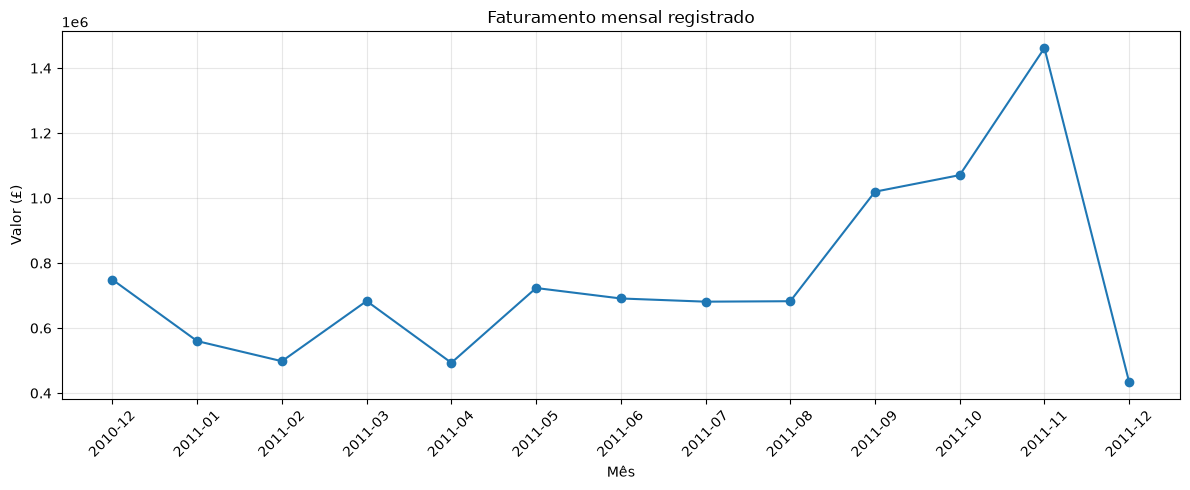

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    faturamento_mensal["Mes"].astype(str),
    faturamento_mensal["TotalVenda"],
    marker="o"
)

plt.title("Faturamento mensal registrado")
plt.xlabel("Mês")
plt.ylabel("Valor (£)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [17]:
# Resumo dos principais problemas nos dados

print("Total de registros:", len(df))

print(
    "Registros sem descrição:",
    df["Description"].isna().sum()
)

print(
    "Registros sem identificação do cliente:",
    df["CustomerID"].isna().sum()
)

print(
    "Registros com quantidade menor ou igual a zero:",
    (df["Quantity"] <= 0).sum()
)

print(
    "Registros com preço menor ou igual a zero:",
    (df["UnitPrice"] <= 0).sum()
)

Total de registros: 541909
Registros sem descrição: 1454
Registros sem identificação do cliente: 135080
Registros com quantidade menor ou igual a zero: 10624
Registros com preço menor ou igual a zero: 2517


In [18]:
# Investigar registros com quantidade inválida
quantidade_invalida = df[df["Quantity"] <= 0]

quantidade_invalida[
    ["InvoiceNo", "StockCode", "Description",
     "Quantity", "UnitPrice", "TotalVenda"]
].head(15)

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,TotalVenda
141,C536379,D,Discount,-1,27.50,-27.50
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,4.65,-4.65
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,1.65,-19.80
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,0.29,-6.96
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,0.29,-6.96
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,0.29,-6.96
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,3.45,-41.40
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,1.65,-19.80
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,1.65,-39.60
939,C536506,22960,JAM MAKING SET WITH JARS,-6,4.25,-25.50


In [19]:
# Investigar registros com preço menor ou igual a zero

precos_invalidos = df[df["UnitPrice"] <= 0]

precos_invalidos[
    [
        "InvoiceNo",
        "StockCode",
        "Description",
        "Quantity",
        "UnitPrice",
        "TotalVenda"
    ]
].head(20)

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,TotalVenda
622,536414,22139,NaN,56,0.0,0.0
1970,536545,21134,NaN,1,0.0,0.0
1971,536546,22145,NaN,1,0.0,0.0
1972,536547,37509,NaN,1,0.0,0.0
1987,536549,85226A,NaN,1,0.0,0.0
1988,536550,85044,NaN,1,0.0,0.0
2024,536552,20950,NaN,1,0.0,0.0
2025,536553,37461,NaN,3,0.0,0.0
2026,536554,84670,NaN,23,0.0,0.0
2406,536589,21777,NaN,-10,0.0,-0.0


In [20]:
# Criar uma base separada para análise de vendas positivas

df_analise = df[
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0)
].copy()

# Recalcular o total de cada linha
df_analise["TotalVenda"] = (
    df_analise["Quantity"] * df_analise["UnitPrice"]
)

# Comparar o tamanho das bases
print("Registros originais:", len(df))
print("Registros na base de análise:", len(df_analise))
print("Registros excluídos da visão de vendas positivas:",
      len(df) - len(df_analise))

# Conferir os primeiros registros
df_analise.head()

Registros originais: 541909
Registros na base de análise: 530104
Registros excluídos da visão de vendas positivas: 11805


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalVenda,Mes
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,2010-12
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,2010-12
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12


In [21]:
# Indicadores gerais de vendas

faturamento_total = df_analise["TotalVenda"].sum()
unidades_vendidas = df_analise["Quantity"].sum()
total_faturas = df_analise["InvoiceNo"].nunique()
total_produtos = df_analise["StockCode"].nunique()

print(f"Faturamento das vendas positivas: £ {faturamento_total:,.2f}")
print(f"Unidades vendidas: {unidades_vendidas:,}")
print(f"Faturas distintas: {total_faturas:,}")
print(f"Produtos distintos: {total_produtos:,}")

Faturamento das vendas positivas: £ 10,666,684.54
Unidades vendidas: 5,588,376
Faturas distintas: 19,960
Produtos distintos: 3,922


In [22]:
# 10 produtos com maior faturamento

top_produtos = (
    df_analise.groupby("Description")
    .agg(
        Faturamento=("TotalVenda", "sum"),
        UnidadesVendidas=("Quantity", "sum")
    )
    .sort_values("Faturamento", ascending=False)
    .head(10)
    .round(2)
    .reset_index()
)

top_produtos

,Description,Faturamento,UnidadesVendidas
0,DOTCOM POSTAGE,206248.77,706
1,REGENCY CAKESTAND 3 TIER,174484.74,13879
2,"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995
3,WHITE HANGING HEART T-LIGHT HOLDER,106292.77,37891
4,PARTY BUNTING,99504.33,18295
5,JUMBO BAG RED RETROSPOT,94340.05,48474
6,MEDIUM CERAMIC TOP STORAGE JAR,81700.92,78033
7,Manual,78112.82,7225
8,POSTAGE,78101.88,3150
9,RABBIT NIGHT LIGHT,66964.99,30788


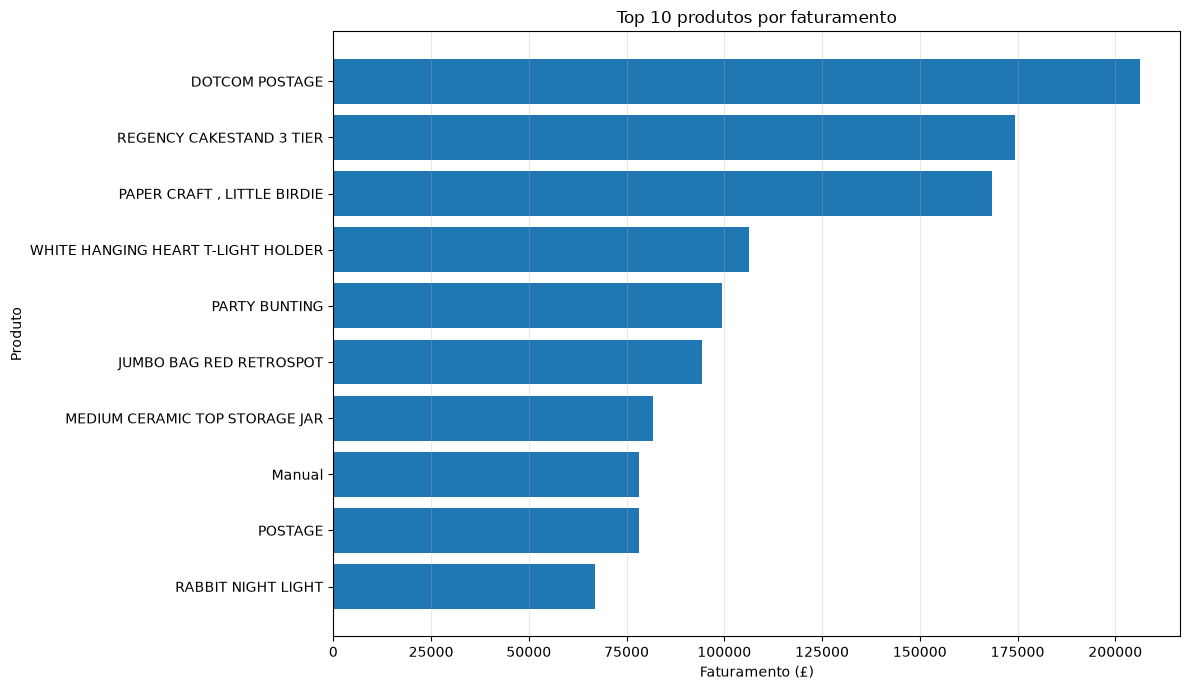

In [23]:
import matplotlib.pyplot as plt

# Ordenar para exibir o maior faturamento no topo
grafico_produtos = top_produtos.sort_values("Faturamento")

plt.figure(figsize=(12, 7))

plt.barh(
    grafico_produtos["Description"],
    grafico_produtos["Faturamento"]
)

plt.title("Top 10 produtos por faturamento")
plt.xlabel("Faturamento (£)")
plt.ylabel("Produto")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [24]:
# Faturamento e volume de vendas por país

vendas_por_pais = (
    df_analise.groupby("Country")
    .agg(
        Faturamento=("TotalVenda", "sum"),
        UnidadesVendidas=("Quantity", "sum"),
        Faturas=("InvoiceNo", "nunique")
    )
    .sort_values("Faturamento", ascending=False)
    .round(2)
    .reset_index()
)

vendas_por_pais.head(10)

,Country,Faturamento,UnidadesVendidas,Faturas
0,United Kingdom,9025222.08,4662390,18019
1,Netherlands,285446.34,200361,94
2,EIRE,283453.96,147173,288
3,Germany,228867.14,119261,457
4,France,209715.11,112103,392
5,Australia,138521.31,83901,57
6,Spain,61577.11,27940,90
7,Switzerland,57089.90,30629,54
8,Belgium,41196.34,23237,98
9,Sweden,38378.33,36083,36


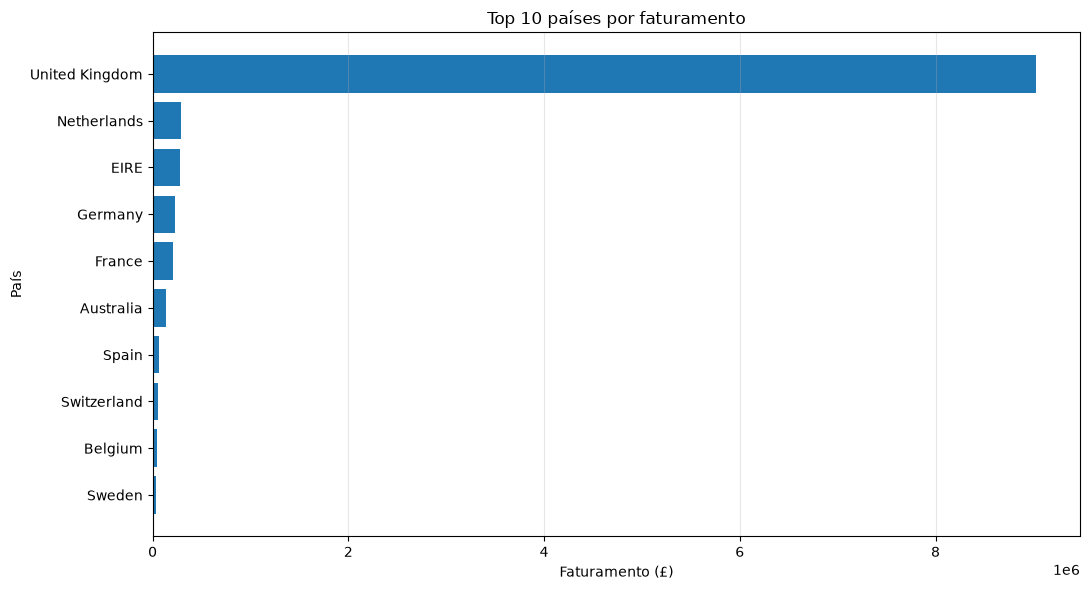

In [25]:
import matplotlib.pyplot as plt

# Selecionar os 10 países com maior faturamento
grafico_paises = vendas_por_pais.head(10).sort_values("Faturamento")

plt.figure(figsize=(11, 6))

plt.barh(
    grafico_paises["Country"],
    grafico_paises["Faturamento"]
)

plt.title("Top 10 países por faturamento")
plt.xlabel("Faturamento (£)")
plt.ylabel("País")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [26]:
# Calcular o valor médio por fatura em cada país

ticket_medio_pais = (
    vendas_por_pais.assign(
        TicketMedio=lambda tabela:
            tabela["Faturamento"] / tabela["Faturas"]
    )
    .sort_values("TicketMedio", ascending=False)
    .round(2)
    .reset_index(drop=True)
)

ticket_medio_pais[
    ["Country", "Faturamento", "Faturas", "TicketMedio"]
].head(10)

,Country,Faturamento,Faturas,TicketMedio
0,Singapore,21279.29,7,3039.90
1,Netherlands,285446.34,94,3036.66
2,Australia,138521.31,57,2430.20
3,Japan,37416.37,19,1969.28
4,Lebanon,1693.88,1,1693.88
5,Hong Kong,15691.80,11,1426.53
6,Brazil,1143.60,1,1143.60
7,Sweden,38378.33,36,1066.06
8,Switzerland,57089.90,54,1057.22
9,Denmark,18955.34,18,1053.07


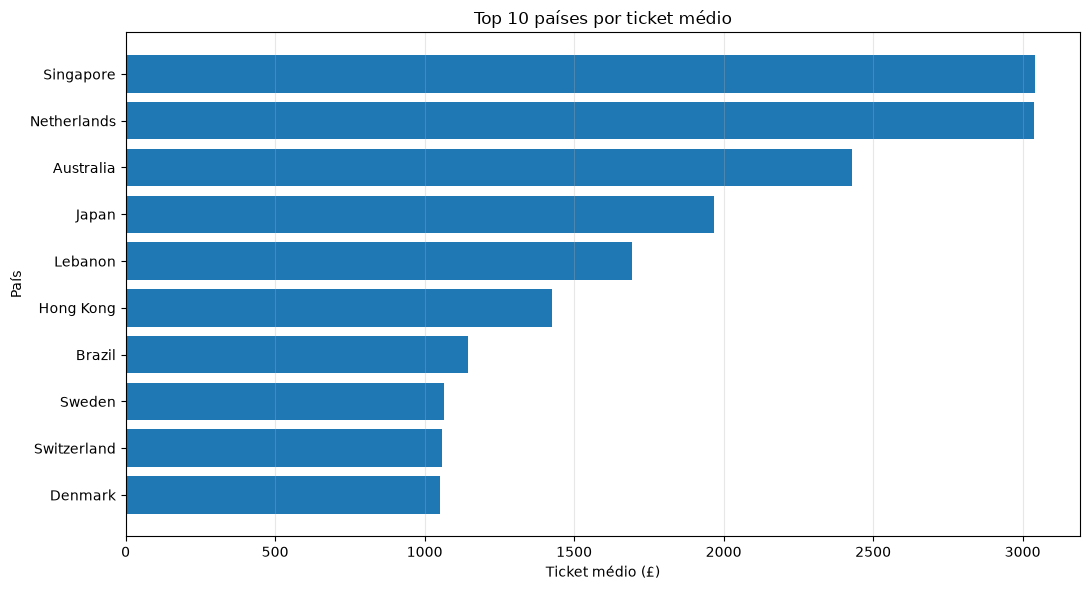

In [27]:
import matplotlib.pyplot as plt

grafico_ticket = ticket_medio_pais.head(10).sort_values(
    "TicketMedio"
)

plt.figure(figsize=(11, 6))

plt.barh(
    grafico_ticket["Country"],
    grafico_ticket["TicketMedio"]
)

plt.title("Top 10 países por ticket médio")
plt.xlabel("Ticket médio (£)")
plt.ylabel("País")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [28]:
# Calcular o faturamento mensal da base de análise

faturamento_mensal_analise = (
    df_analise.groupby("Mes")["TotalVenda"]
    .sum()
    .round(2)
    .reset_index()
)

faturamento_mensal_analise

,Mes,TotalVenda
0,2010-12,823746.14
1,2011-01,691364.56
2,2011-02,523631.89
3,2011-03,717639.36
4,2011-04,537808.62
5,2011-05,770536.02
6,2011-06,761739.90
7,2011-07,719221.19
8,2011-08,759138.38
9,2011-09,1058590.17


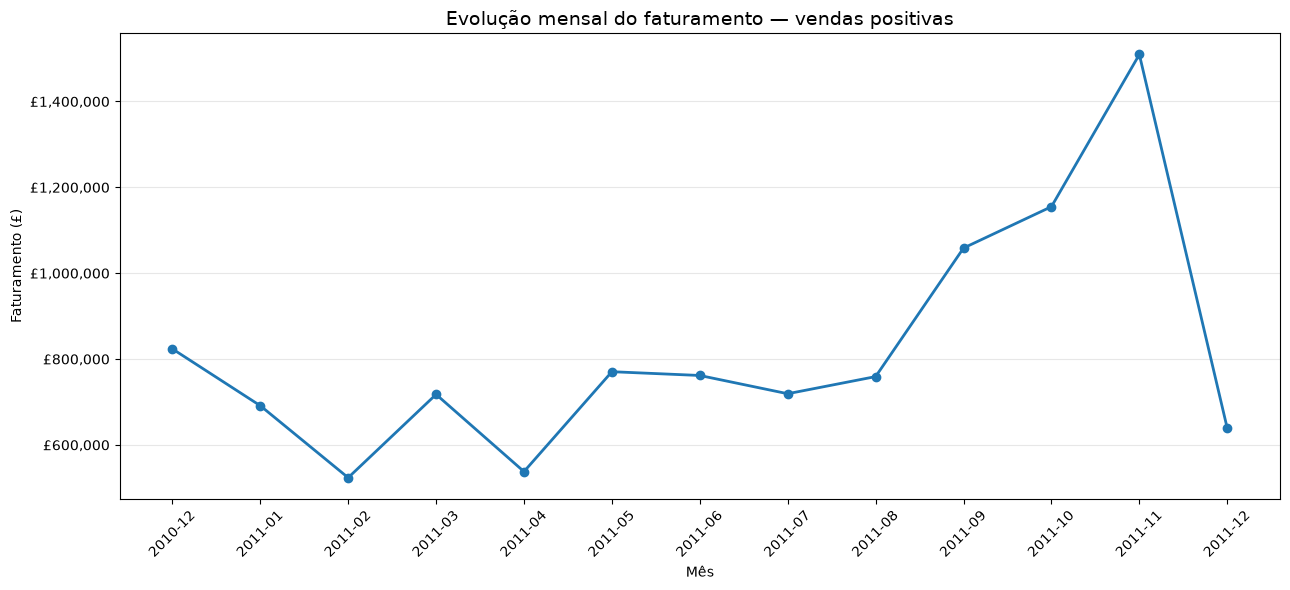

In [29]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

dados_grafico = faturamento_mensal_analise.copy()
dados_grafico["Mes"] = dados_grafico["Mes"].astype(str)

fig, ax = plt.subplots(figsize=(13, 6))

ax.plot(
    dados_grafico["Mes"],
    dados_grafico["TotalVenda"],
    marker="o",
    linewidth=2
)

ax.set_title(
    "Evolução mensal do faturamento — vendas positivas",
    fontsize=14
)
ax.set_xlabel("Mês")
ax.set_ylabel("Faturamento (£)")
ax.yaxis.set_major_formatter(
    mtick.StrMethodFormatter("£{x:,.0f}")
)

ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [30]:
print("Primeira data:", df["InvoiceDate"].min())
print("Última data:", df["InvoiceDate"].max())

print(
    "Dias distintos registrados em dezembro de 2011:",
    df.loc[
        (df["InvoiceDate"].dt.year == 2011) &
        (df["InvoiceDate"].dt.month == 12),
        "InvoiceDate"
    ].dt.day.nunique()
)

Primeira data: 2010-12-01 08:26:00
Última data: 2011-12-09 12:50:00
Dias distintos registrados em dezembro de 2011: 8


In [31]:
# Verificar as vendas por dia em dezembro de 2011

vendas_dezembro = df_analise[
    (df_analise["InvoiceDate"].dt.year == 2011) &
    (df_analise["InvoiceDate"].dt.month == 12)
].copy()

vendas_dezembro["Dia"] = vendas_dezembro["InvoiceDate"].dt.day

vendas_por_dia = (
    vendas_dezembro
    .groupby("Dia")["TotalVenda"]
    .sum()
    .round(2)
    .reset_index()
)

vendas_por_dia

,Dia,TotalVenda
0,1,52197.25
1,2,57664.07
2,4,24621.43
3,5,88741.96
4,6,56713.21
5,7,75439.16
6,8,82495.00
7,9,200920.60


In [32]:
resumo_dezembro = (
    vendas_dezembro
    .groupby("Dia")
    .agg(
        Faturamento=("TotalVenda", "sum"),
        Faturas=("InvoiceNo", "nunique"),
        UnidadesVendidas=("Quantity", "sum")
    )
    .round(2)
    .reset_index()
)

resumo_dezembro

,Dia,Faturamento,Faturas,UnidadesVendidas
0,1,52197.25,121,27051
1,2,57664.07,120,28797
2,4,24621.43,66,12410
3,5,88741.96,127,44578
4,6,56713.21,115,30468
5,7,75439.16,106,41880
6,8,82495.00,120,35085
7,9,200920.60,44,93979


In [33]:
# Investigar as maiores faturas de 9 de dezembro de 2011

maiores_faturas_dia9 = (
    vendas_dezembro[vendas_dezembro["Dia"] == 9]
    .groupby("InvoiceNo")
    .agg(
        Faturamento=("TotalVenda", "sum"),
        Unidades=("Quantity", "sum"),
        Itens=("StockCode", "nunique")
    )
    .sort_values("Faturamento", ascending=False)
    .head(10)
    .round(2)
    .reset_index()
)

maiores_faturas_dia9

,InvoiceNo,Faturamento,Unidades,Itens
0,581483,168469.60,80995,1
1,581492,7689.23,2011,731
2,581498,5664.89,732,218
3,581497,3217.20,654,56
4,581476,2618.89,2215,65
5,581495,1203.90,276,15
6,581579,903.62,476,30
7,581578,848.55,508,38
8,581485,741.90,114,3
9,581496,598.97,496,32


df.loc[
    df["InvoiceNo"].astype(str) == "581483",
    [
        "InvoiceNo",
        "StockCode",
        "Description",
        "Quantity",
        "UnitPrice",
        "CustomerID",
        "Country",
        "InvoiceDate",
        "TotalVenda"
    ]
]

In [34]:
df.loc[
    df["InvoiceNo"].astype(str) == "581483",
    [
        "InvoiceNo",
        "StockCode",
        "Description",
        "Quantity",
        "UnitPrice",
        "CustomerID",
        "Country",
        "InvoiceDate",
        "TotalVenda"
    ]
]

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID,Country,InvoiceDate,TotalVenda
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,16446.0,United Kingdom,2011-12-09 09:15:00,168469.6


In [35]:
# Investigar a fatura e o contexto do registro excepcional

fatura_581483 = df[
    df["InvoiceNo"].astype(str) == "581483"
]

display(fatura_581483)

print("Quantidade de linhas na fatura:", len(fatura_581483))
print("Total calculado da fatura:", fatura_581483["TotalVenda"].sum())

display(
    df[
        (df["CustomerID"] == 16446) &
        (df["StockCode"].astype(str) == "23843")
    ][
        [
            "InvoiceNo",
            "InvoiceDate",
            "Description",
            "Quantity",
            "UnitPrice",
            "Country"
        ]
    ].sort_values("InvoiceDate")
)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalVenda,Mes
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446.0,United Kingdom,168469.6,2011-12


Quantidade de linhas na fatura: 1
Total calculado da fatura: 168469.6


,InvoiceNo,InvoiceDate,Description,Quantity,UnitPrice,Country
540421,581483,2011-12-09 09:15:00,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,United Kingdom
540422,C581484,2011-12-09 09:27:00,"PAPER CRAFT , LITTLE BIRDIE",-80995,2.08,United Kingdom


In [36]:
# Comparar o impacto da venda excepcional e do cancelamento

valor_excepcional = 80995 * 2.08

print(f"Valor da venda: £ {valor_excepcional:,.2f}")
print(f"Valor do cancelamento: -£ {valor_excepcional:,.2f}")
print(f"Impacto líquido dos dois registros: £ {0:,.2f}")

faturamento_dia9 = vendas_dezembro.loc[
    vendas_dezembro["Dia"] == 9,
    "TotalVenda"
].sum()

print(f"Faturamento positivo registrado no dia 9: £ {faturamento_dia9:,.2f}")
print(
    "Faturamento do dia 9 sem a venda excepcional: "
    f"£ {faturamento_dia9 - valor_excepcional:,.2f}"
)

Valor da venda: £ 168,469.60
Valor do cancelamento: -£ 168,469.60
Impacto líquido dos dois registros: £ 0.00
Faturamento positivo registrado no dia 9: £ 200,920.60
Faturamento do dia 9 sem a venda excepcional: £ 32,451.00


In [37]:
# Resumo dos principais indicadores da análise

print("===== RESUMO DA ANÁLISE DE VENDAS =====")
print(f"Registros na base original: {len(df):,}")
print(f"Registros na base de vendas positivas: {len(df_analise):,}")
print(f"Faturamento das vendas positivas: £ {df_analise['TotalVenda'].sum():,.2f}")
print(f"Unidades vendidas na base de análise: {df_analise['Quantity'].sum():,}")
print(f"Faturas distintas: {df_analise['InvoiceNo'].nunique():,}")
print(f"Produtos distintos: {df_analise['StockCode'].nunique():,}")
print(f"Países distintos: {df_analise['Country'].nunique():,}")
print(f"Primeira data: {df['InvoiceDate'].min()}")
print(f"Última data: {df['InvoiceDate'].max()}")

===== RESUMO DA ANÁLISE DE VENDAS =====
Registros na base original: 541,909
Registros na base de vendas positivas: 530,104
Faturamento das vendas positivas: £ 10,666,684.54
Unidades vendidas na base de análise: 5,588,376
Faturas distintas: 19,960
Produtos distintos: 3,922
Países distintos: 38
Primeira data: 2010-12-01 08:26:00
Última data: 2011-12-09 12:50:00


## Conclusões da Análise Exploratória de Vendas

### Objetivo
Analisar os dados de vendas para identificar padrões de faturamento, produtos de destaque, distribuição geográfica e possíveis problemas de qualidade dos dados.

### Principais resultados
- A base original contém 541.909 registros, abrangendo o período de 1º de dezembro de 2010 a 9 de dezembro de 2011.
- A base utilizada para a análise de vendas positivas contém 530.104 registros e apresenta faturamento registrado de £ 10.666.684,54.
- Foram identificadas 19.960 faturas distintas, 3.922 códigos de produtos e registros distribuídos por 38 países.
- O Reino Unido apresentou o maior faturamento entre os países analisados.
- Novembro de 2011 foi o mês com maior faturamento registrado na análise mensal.
- A investigação de qualidade dos dados identificou uma venda excepcional de 80.995 unidades, seguida de um cancelamento correspondente 12 minutos depois. Os dois registros apresentam valores iguais e sinais opostos, anulando-se financeiramente.

### Limitações e cuidados
A base de análise considera somente registros com quantidade e preço unitário positivos. Portanto, o faturamento calculado não deve ser interpretado como faturamento líquido definitivo, pois os cancelamentos foram excluídos dessa visão.

Dezembro de 2011 está incompleto, com registros até o dia 9. Comparações desse mês com meses completos devem ser feitas com cautela.

Valores atípicos não devem ser excluídos automaticamente: é necessário investigar seu contexto e documentar os critérios adotados.

### Conclusão
A análise exploratória permitiu identificar padrões de vendas, produtos e mercados relevantes, além de demonstrar como problemas de qualidade dos dados podem afetar indicadores de negócio. Como continuidade, recomenda-se aprofundar a análise de cancelamentos, validar os critérios de cálculo do faturamento líquido e desenvolver visualizações executivas para apoiar a tomada de decisão.